# Amazon UK Product Analysis

## Business Objective

The purpose of this analysis is to examine the Amazon UK product catalogue and identify useful trends in product categories, pricing, and customer ratings.

The analysis focuses on the following business questions:

- Which product categories contain the most products?
- What price range contains most products?
- Are there unusually expensive products?
- How are customer ratings distributed?
- Which ratings are most common?

# 1. Understanding Product Categories

In [2]:
%pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Program Files\Python39\python.exe -m pip install --upgrade pip' command.


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

C:\Users\kahau\AppData\Roaming\Python\Python39\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 117M/117M [00:04<00:00, 25.2MB/s] 

Extracting files...


Path to dataset files: C:\Users\kahau\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [6]:
os.listdir(path)

['amz_uk_price_prediction_dataset.csv']

In [8]:
import pandas as pd
import os

file_path = os.path.join(
    path,
    "amz_uk_price_prediction_dataset.csv"
)

df = pd.read_csv(file_path)

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Dataset Overview

The dataset contains Amazon UK product information, including product categories, prices, star ratings, and other product-level attributes.

Initial exploration was conducted to understand the number of records, column types, missing values, and basic descriptive statistics.

In [41]:
df.shape
df.info()
df.head()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [9]:
df["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [10]:
frequency_table = (
    df["category"]
    .value_counts()
    .reset_index()
)

frequency_table.columns = ["category", "frequency"]

frequency_table

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Motorbike Chassis,107
292,Alexa Built-In Devices,107
293,Plugs,107
294,Smart Home Security & Lighting,104


In [12]:
frequency_table.head(5)

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


In [13]:
frequency_table_top_10=frequency_table.head(10)

In [14]:
frequency_table_top_10

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
5,Manicure & Pedicure Products,18940
6,Skin Care,18769
7,Make-up,18756
8,Hair Care,18735
9,Fragrances,18564


<Axes: xlabel='category'>

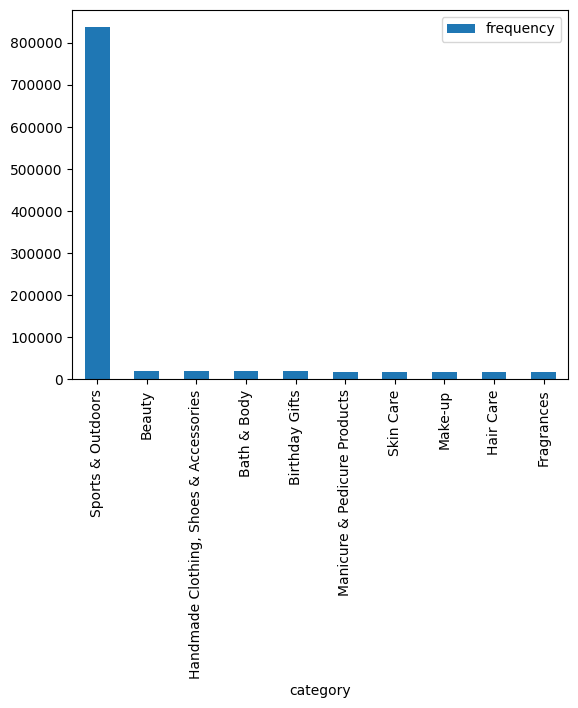

In [15]:
frequency_table_top_10.plot(
    x="category",
    y="frequency",
    kind="bar"
)

<Axes: ylabel='frequency'>

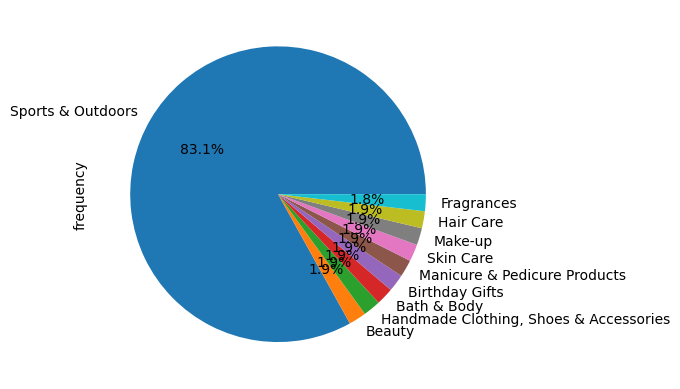

In [19]:
frequency_table_top_10.plot(
    y="frequency",
    kind="pie",
    labels=frequency_table_top_10["category"],
    autopct="%1.1f%%",
    legend=False
)

Sports and Outdoors dominates the categories with 83.1% of the pie chart. 

## Product Category Findings

The category frequency analysis shows that some categories contain substantially more products than others. This means the Amazon UK catalogue is not evenly distributed across product types.

From a business perspective, the largest categories may represent highly competitive markets with strong customer demand. Smaller categories may represent either niche opportunities or areas with limited product availability.

Businesses entering the platform should consider both category size and competition rather than assuming that the largest category is automatically the best opportunity.

In [20]:
print(df["price"].mean())
print(df["price"].median())
print(df["price"].mode())

89.24380943923663
19.09
0    9.99
Name: price, dtype: float64


The mean of the prices is much higher than the mean and mode. This implies that the mean is heavily influenced by expensive outliers. 

In [23]:
price_statistics=df["price"].describe()

In [25]:
price_statistics

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

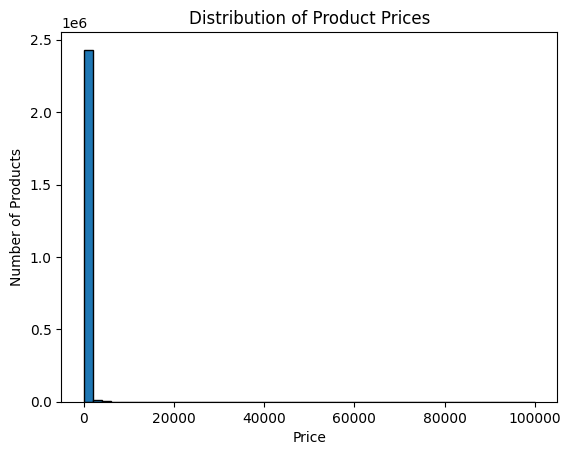

In [28]:
import matplotlib.pyplot as plt

df["price"].dropna().plot(
    kind="hist",
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

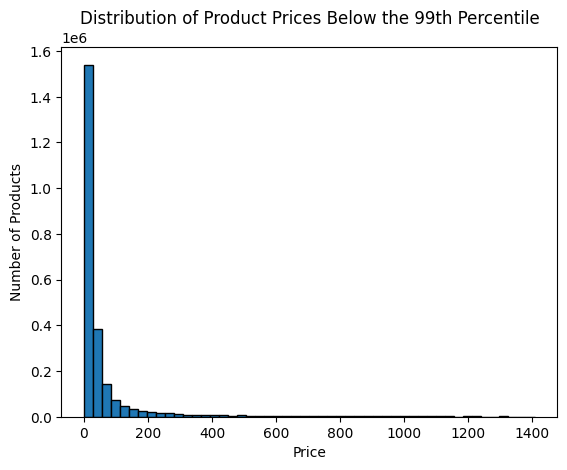

In [29]:
import matplotlib.pyplot as plt

price_cutoff = df["price"].quantile(0.99)

df.loc[df["price"] <= price_cutoff, "price"].plot(
    kind="hist",
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Product Prices Below the 99th Percentile")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

## Product Price Distribution

The original price histogram was difficult to interpret because a small number of extremely expensive products stretched the horizontal axis. Most products were compressed into the lowest price range.

After limiting the visualization to prices below the 99th percentile, the typical product-price distribution became much clearer.

The distribution is strongly right-skewed. Most products are concentrated within lower price ranges, while a relatively small number of products have substantially higher prices.

From a business perspective, this suggests that the Amazon UK catalogue is primarily made up of lower- and mid-priced products, with a smaller premium-product segment.

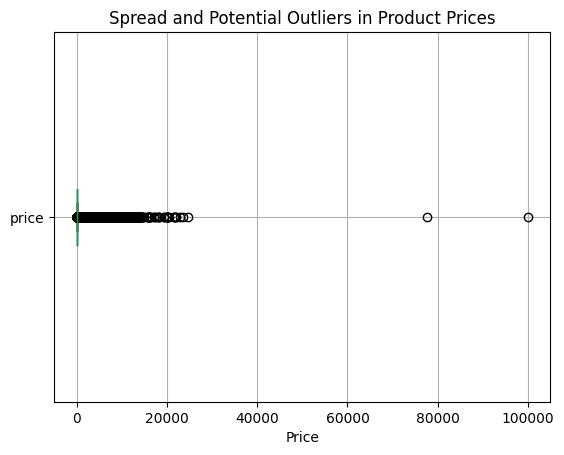

In [31]:
import matplotlib.pyplot as plt

df.boxplot(
    column="price",
    vert=False
)

plt.title("Spread and Potential Outliers in Product Prices")
plt.xlabel("Price")
plt.show()

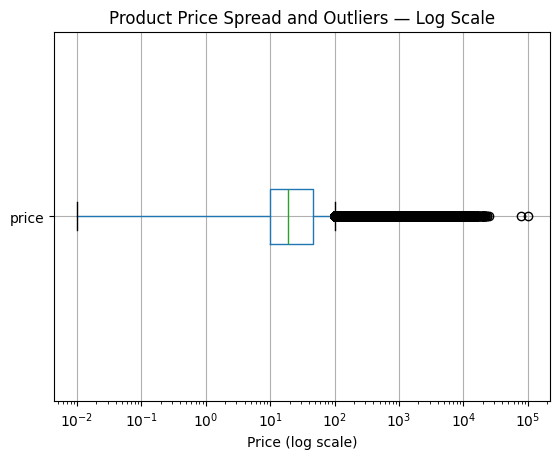

In [32]:
df.loc[df["price"] > 0].boxplot(
    column="price",
    vert=False
)

plt.xscale("log")
plt.title("Product Price Spread and Outliers — Log Scale")
plt.xlabel("Price (log scale)")
plt.show()

## Price Outliers

The box plot confirms that there are many products priced significantly higher than the typical product.

Two particularly extreme products appear near £78,000 and £100,000. These values may represent genuine luxury or specialized products, but they may also require additional investigation for possible data-quality issues.

For business analysis, extreme prices should not automatically be deleted. They should first be reviewed to determine whether they represent valid premium products, incorrect values, or products that belong to a fundamentally different market segment.

In [38]:
print(df["stars"].mean())
print(df["stars"].median())
print(df["stars"].mode())

2.152836472966065
0.0
0    0.0
Name: stars, dtype: float64


In [37]:
df["stars"].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [39]:
df["stars"].unique()

array([4.7, 4.6, 4.5, 4.8, 0. , 4.4, 4.3, 4.1, 4.9, 5. , 3.8, 3.6, 4. ,
       4.2, 3. , 3.9, 2.5, 3.4, 3.7, 3.2, 3.3, 3.5, 2.7, 2.1, 1. , 3.1,
       2. , 2.9, 2.8, 1.5, 2.2, 2.3, 2.6, 2.4, 1.4, 1.9, 1.8, 1.7, 1.6,
       1.2, 1.3, 1.1])

Product ratings show a large concentration at zero, likely representing unrated products. Among products with actual ratings, scores are generally high and cluster around 4 to 5 stars. Therefore, the overall mean rating of 2.15 understates customer satisfaction because it includes many unrated products coded as zero.

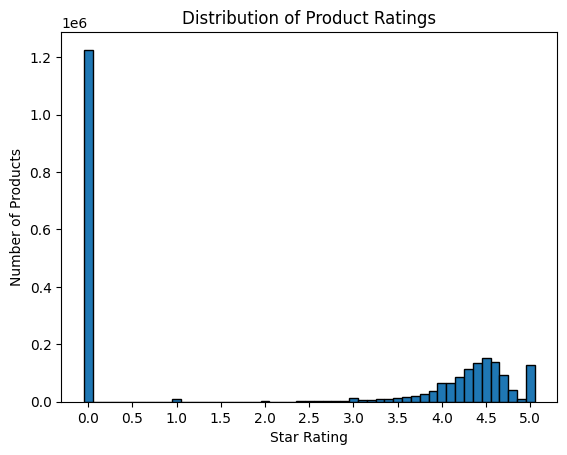

In [40]:
import numpy as np
import matplotlib.pyplot as plt

ratings = df["stars"].dropna()

bins = np.arange(-0.05, 5.15, 0.1)

ratings.plot(
    kind="hist",
    bins=bins,
    edgecolor="black"
)

plt.title("Distribution of Product Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Products")
plt.xticks(np.arange(0, 5.1, 0.5))
plt.show()

## Product Rating Distribution

The ratings analysis shows that a large proportion of products have a value of 0.0 stars. Because Amazon ratings normally use a one-to-five-star scale, these zero values most likely represent products that have not yet received a rating rather than products with extremely poor customer reviews.

Including these zero values reduces the overall average rating to approximately 2.15 stars and makes the mean misleading.

When unrated products are excluded, customer ratings are concentrated toward the upper end of the scale, particularly between 4 and 5 stars. This suggests that products with recorded reviews generally receive positive customer feedback.

From a business perspective, unrated products should be analyzed separately from poorly rated products. Sellers may benefit from encouraging verified customers to leave reviews, particularly for products that currently have no rating.

In [42]:
rated_products = df.loc[df["stars"] > 0, "stars"]

print("Most common actual rating:", rated_products.mode()[0])
print("Frequency:", rated_products.value_counts().iloc[0])

Most common actual rating: 4.5
Frequency: 151577


The most common rating among products with recorded ratings was **4.5 stars**.

This supports the conclusion that rated products generally receive favorable customer feedback.

## Business Recommendations

### Pricing strategy

Businesses should benchmark products against the typical price range within their specific category rather than against the entire Amazon catalogue. The overall dataset contains extreme price differences between product types.

### Premium product investigation

Products with unusually high prices should be reviewed separately. These products may represent premium market segments, specialized equipment, or potential data-quality problems.

### Review acquisition

Products with 0.0 stars should be treated as unrated rather than poorly rated. Sellers could improve product credibility by encouraging verified purchasers to submit reviews.

### Category selection

Large categories may offer strong demand but also greater competition. Smaller categories may provide niche opportunities, although demand should be investigated before making business decisions.